In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn
import streamlit as st

print("All libraries imported successfully!")
print("NumPy:", np.__version__)
print("Pandas:", pd.__version__)
print("Scikit-learn:", sklearn.__version__)

All libraries imported successfully!
NumPy: 2.5.4
Pandas: 3.1.1
Scikit-learn: 1.9.1


In [2]:
import pandas as pd

# Dataset file location
file_path = "../dataset/raw/household_power_consumption.txt"

# Load dataset
df = pd.read_csv(
    file_path,
    sep=";",
    low_memory=False,
    na_values="?"
)

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

# Display first 5 rows
df.head()

Dataset loaded successfully!
Dataset shape: (2075259, 9)


,Date,Time,Global_active_power,Global_reactive_power,Voltage,Global_intensity,Sub_metering_1,Sub_metering_2,Sub_metering_3
0,16/12/2006,17:24:00,4.216,0.418,234.84,18.4,0.0,1.0,17.0
1,16/12/2006,17:25:00,5.360,0.436,233.63,23.0,0.0,1.0,16.0
2,16/12/2006,17:26:00,5.374,0.498,233.29,23.0,0.0,2.0,17.0
3,16/12/2006,17:27:00,5.388,0.502,233.74,23.0,0.0,1.0,17.0
4,16/12/2006,17:28:00,3.666,0.528,235.68,15.8,0.0,1.0,17.0


In [3]:
# Check dataset information
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 2075259 entries, 0 to 2075258
Data columns (total 9 columns):
 #   Column                 Dtype  
---  ------                 -----  
 0   Date                   str    
 1   Time                   str    
 2   Global_active_power    float64
 3   Global_reactive_power  float64
 4   Voltage                float64
 5   Global_intensity       float64
 6   Sub_metering_1         float64
 7   Sub_metering_2         float64
 8   Sub_metering_3         float64
dtypes: float64(7), str(2)
memory usage: 176.0 MB


In [4]:
# Check number of rows and columns
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

# Check column names
print("\nColumn names:")
print(df.columns.tolist())

Number of rows: 2075259
Number of columns: 9

Column names:
['Date', 'Time', 'Global_active_power', 'Global_reactive_power', 'Voltage', 'Global_intensity', 'Sub_metering_1', 'Sub_metering_2', 'Sub_metering_3']


In [5]:
# Count missing values in each column
print(df.isnull().sum())

Date                         0
Time                         0
Global_active_power      25979
Global_reactive_power    25979
Voltage                  25979
Global_intensity         25979
Sub_metering_1           25979
Sub_metering_2           25979
Sub_metering_3           25979
dtype: int64


In [6]:
# Create a copy of the original dataset
df_clean = df.copy()

# Remove rows containing missing values
df_clean = df_clean.dropna()

# Check the new dataset size
print("Original dataset shape:", df.shape)
print("Cleaned dataset shape:", df_clean.shape)

# Check remaining missing values
print("\nMissing values after cleaning:")
print(df_clean.isnull().sum().sum())

Original dataset shape: (2075259, 9)
Cleaned dataset shape: (2049280, 9)

Missing values after cleaning:
0


In [7]:
# Combine Date and Time into a single DateTime column
df_clean['DateTime'] = pd.to_datetime(
    df_clean['Date'] + ' ' + df_clean['Time'],
    format='%d/%m/%Y %H:%M:%S'
)

# Display first five records
print(df_clean[['Date', 'Time', 'DateTime']].head())

# Check the datatype
print("\nDateTime data type:", df_clean['DateTime'].dtype)

         Date      Time            DateTime
0  16/12/2006  17:24:00 2006-12-16 17:24:00
1  16/12/2006  17:25:00 2006-12-16 17:25:00
2  16/12/2006  17:26:00 2006-12-16 17:26:00
3  16/12/2006  17:27:00 2006-12-16 17:27:00
4  16/12/2006  17:28:00 2006-12-16 17:28:00

DateTime data type: datetime64[us]


In [8]:
# Extract time-based features
df_clean['Hour'] = df_clean['DateTime'].dt.hour
df_clean['Day'] = df_clean['DateTime'].dt.day
df_clean['Month'] = df_clean['DateTime'].dt.month
df_clean['Year'] = df_clean['DateTime'].dt.year
df_clean['DayOfWeek'] = df_clean['DateTime'].dt.day_name()

# Display the new columns
print(df_clean[['DateTime', 'Hour', 'Day', 'Month',
                'Year', 'DayOfWeek']].head())

             DateTime  Hour  Day  Month  Year DayOfWeek
0 2006-12-16 17:24:00    17   16     12  2006  Saturday
1 2006-12-16 17:25:00    17   16     12  2006  Saturday
2 2006-12-16 17:26:00    17   16     12  2006  Saturday
3 2006-12-16 17:27:00    17   16     12  2006  Saturday
4 2006-12-16 17:28:00    17   16     12  2006  Saturday


In [9]:
# Statistical summary of numerical columns
df_clean.describe()

,Global_active_power,Global_reactive_power,Voltage,Global_intensity,Sub_metering_1,Sub_metering_2,Sub_metering_3,DateTime,Hour,Day,Month,Year
count,2.049280e+06,2.049280e+06,2.049280e+06,2.049280e+06,2.049280e+06,2.049280e+06,2.049280e+06,2049280,2.049280e+06,2.049280e+06,2.049280e+06,2.049280e+06
mean,1.091615e+00,1.237145e-01,2.408399e+02,4.627759e+00,1.121923e+00,1.298520e+00,6.458447e+00,2008-12-02 00:59:44.397739,1.150391e+01,1.571245e+01,6.454433e+00,2.008425e+03
min,7.600000e-02,0.000000e+00,2.232000e+02,2.000000e-01,0.000000e+00,0.000000e+00,0.000000e+00,2006-12-16 17:24:00,0.000000e+00,1.000000e+00,1.000000e+00,2.006000e+03
25%,3.080000e-01,4.800000e-02,2.389900e+02,1.400000e+00,0.000000e+00,0.000000e+00,0.000000e+00,2007-12-10 05:37:45,5.000000e+00,8.000000e+00,3.000000e+00,2.007000e+03
50%,6.020000e-01,1.000000e-01,2.410100e+02,2.600000e+00,0.000000e+00,0.000000e+00,1.000000e+00,2008-11-30 01:22:30,1.200000e+01,1.600000e+01,6.000000e+00,2.008000e+03
75%,1.528000e+00,1.940000e-01,2.428900e+02,6.400000e+00,0.000000e+00,1.000000e+00,1.700000e+01,2009-11-23 20:31:15,1.800000e+01,2.300000e+01,9.000000e+00,2.009000e+03
max,1.112200e+01,1.390000e+00,2.541500e+02,4.840000e+01,8.800000e+01,8.000000e+01,3.100000e+01,2010-11-26 21:02:00,2.300000e+01,3.100000e+01,1.200000e+01,2.010000e+03
std,1.057294e+00,1.127220e-01,3.239987e+00,4.444396e+00,6.153031e+00,5.822026e+00,8.437154e+00,NaN,6.925189e+00,8.801670e+00,3.423209e+00,1.124388e+00


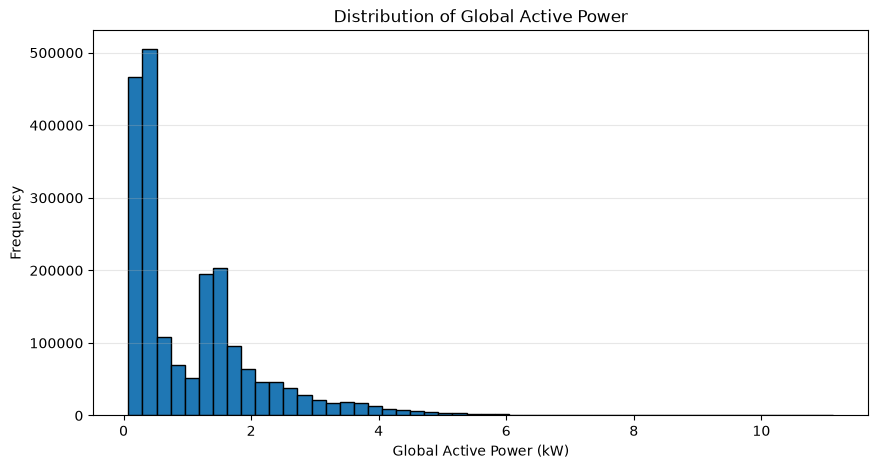

In [10]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))

plt.hist(
    df_clean['Global_active_power'],
    bins=50,
    edgecolor='black'
)

plt.title('Distribution of Global Active Power')
plt.xlabel('Global Active Power (kW)')
plt.ylabel('Frequency')

plt.grid(axis='y', alpha=0.3)
plt.show()

The history saving thread hit an unexpected error (OperationalError('database or disk is full')).History will not be written to the database.


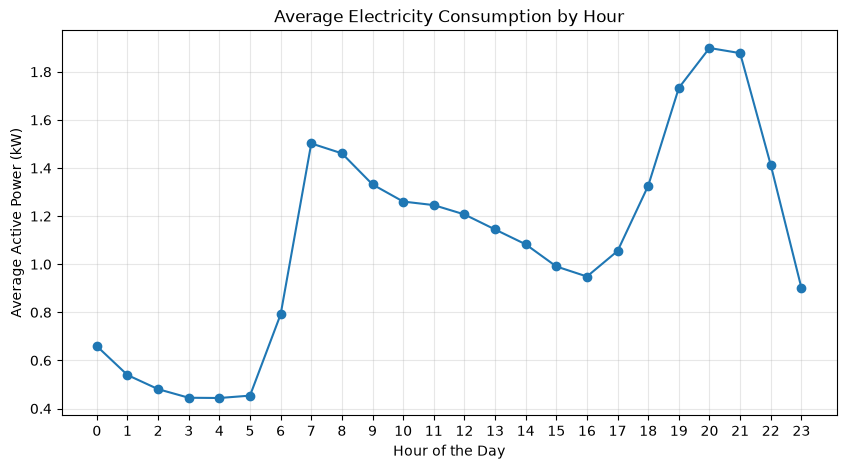

In [11]:
# Calculate average electricity consumption for each hour
hourly_consumption = df_clean.groupby('Hour')['Global_active_power'].mean()

# Create the graph
plt.figure(figsize=(10, 5))

plt.plot(
    hourly_consumption.index,
    hourly_consumption.values,
    marker='o'
)

plt.title('Average Electricity Consumption by Hour')
plt.xlabel('Hour of the Day')
plt.ylabel('Average Active Power (kW)')

plt.xticks(range(0, 24))
plt.grid(True, alpha=0.3)
plt.show()

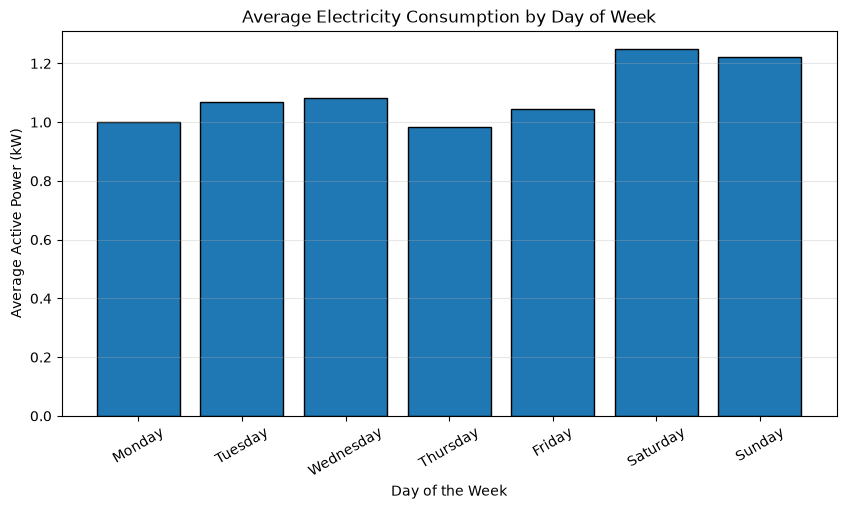

In [12]:
# Calculate average consumption for each day
daily_consumption = df_clean.groupby('DayOfWeek')['Global_active_power'].mean()

# Arrange days in correct order
day_order = [
    'Monday', 'Tuesday', 'Wednesday',
    'Thursday', 'Friday', 'Saturday', 'Sunday'
]

daily_consumption = daily_consumption.reindex(day_order)

# Create bar graph
plt.figure(figsize=(10, 5))

plt.bar(
    daily_consumption.index,
    daily_consumption.values,
    edgecolor='black'
)

plt.title('Average Electricity Consumption by Day of Week')
plt.xlabel('Day of the Week')
plt.ylabel('Average Active Power (kW)')
plt.xticks(rotation=30)
plt.grid(axis='y', alpha=0.3)

plt.show()

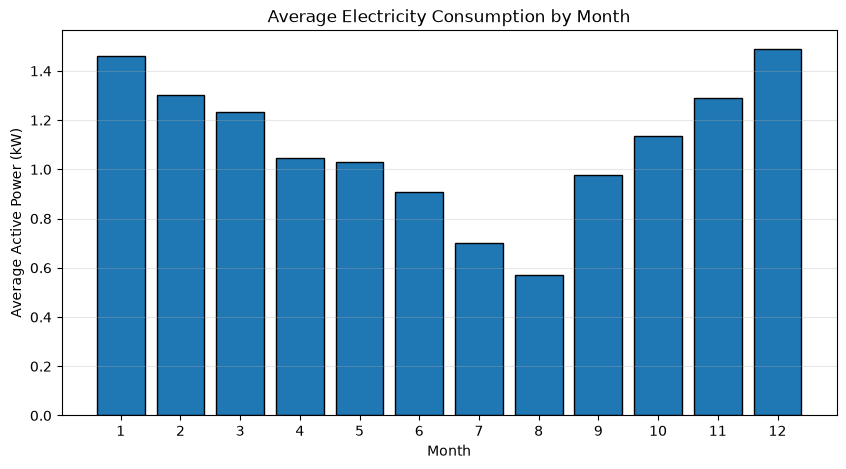

In [13]:
# Calculate average electricity consumption for each month
monthly_consumption = df_clean.groupby('Month')['Global_active_power'].mean()

# Create a bar graph
plt.figure(figsize=(10, 5))

plt.bar(
    monthly_consumption.index,
    monthly_consumption.values,
    edgecolor='black'
)

plt.title('Average Electricity Consumption by Month')
plt.xlabel('Month')
plt.ylabel('Average Active Power (kW)')

plt.xticks(range(1, 13))
plt.grid(axis='y', alpha=0.3)

plt.show()

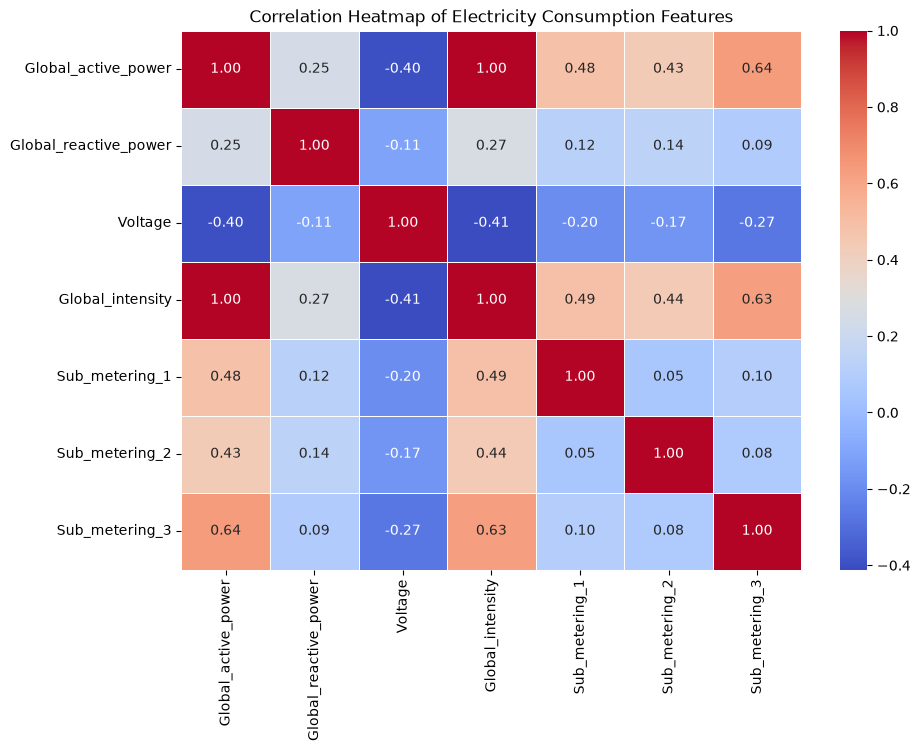

In [14]:
# Select numerical electricity columns
numeric_data = df_clean[
    [
        'Global_active_power',
        'Global_reactive_power',
        'Voltage',
        'Global_intensity',
        'Sub_metering_1',
        'Sub_metering_2',
        'Sub_metering_3'
    ]
]

# Calculate correlation
correlation_matrix = numeric_data.corr()

# Create heatmap
plt.figure(figsize=(10, 7))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap='coolwarm',
    fmt='.2f',
    linewidths=0.5
)

plt.title('Correlation Heatmap of Electricity Consumption Features')
plt.show()

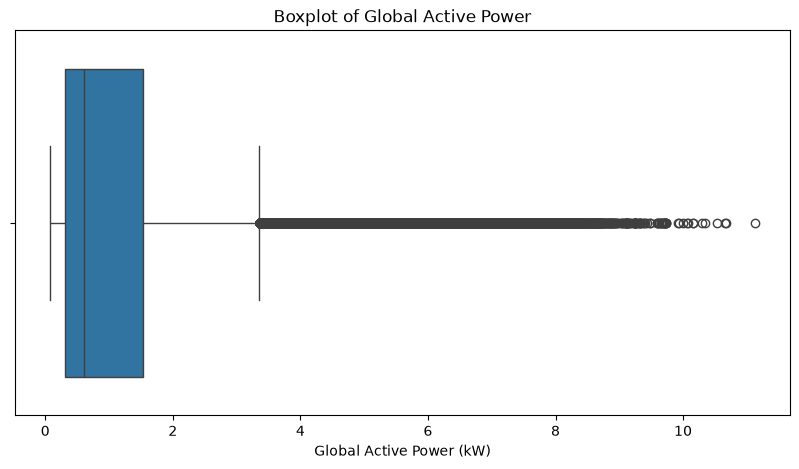

In [15]:
plt.figure(figsize=(10, 5))

sns.boxplot(
    x=df_clean['Global_active_power']
)

plt.title('Boxplot of Global Active Power')
plt.xlabel('Global Active Power (kW)')

plt.show()

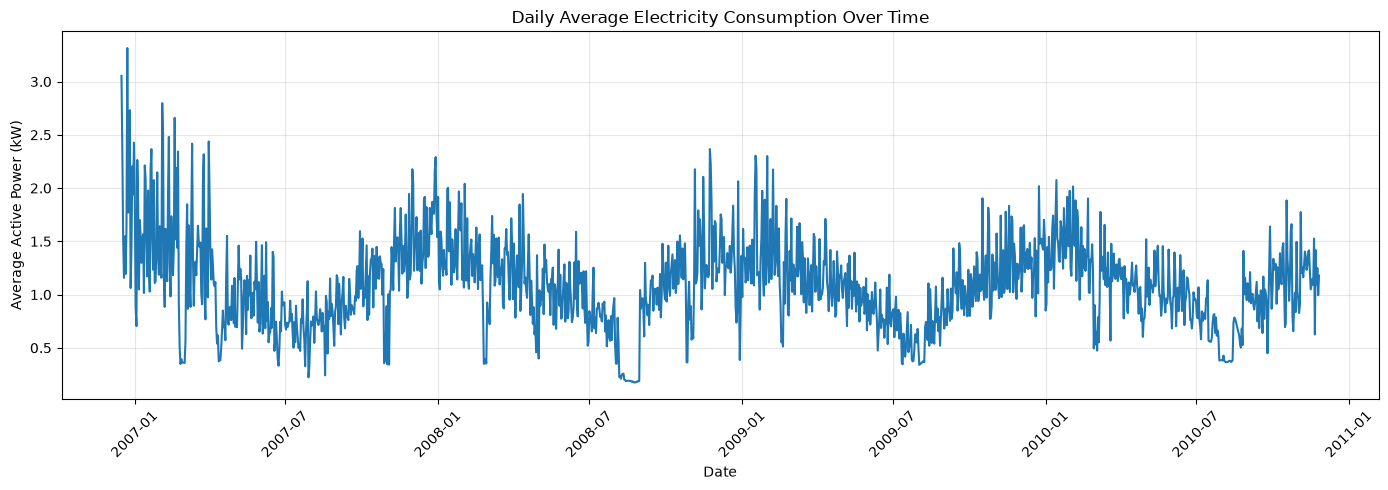

In [16]:
# Calculate daily average electricity consumption
daily_average = df_clean.groupby(
    df_clean['DateTime'].dt.date
)['Global_active_power'].mean()

# Create time-series graph
plt.figure(figsize=(14, 5))

plt.plot(daily_average.index, daily_average.values)

plt.title('Daily Average Electricity Consumption Over Time')
plt.xlabel('Date')
plt.ylabel('Average Active Power (kW)')

plt.xticks(rotation=45)
plt.grid(alpha=0.3)
plt.tight_layout()

plt.show()

In [17]:
# Calculate energy consumed in each minute (kWh)
df_clean['Energy_kWh'] = df_clean['Global_active_power'] / 60

# Calculate total daily energy consumption
daily_energy = df_clean.groupby(
    df_clean['DateTime'].dt.date
)['Energy_kWh'].sum()

# Display first 10 days
print("Daily Electricity Consumption (kWh):")
print(daily_energy.head(10))

Daily Electricity Consumption (kWh):
DateTime
2006-12-16    20.152933
2006-12-17    56.507667
2006-12-18    36.730433
2006-12-19    27.769900
2006-12-20    37.095800
2006-12-21    28.610400
2006-12-22    39.022300
2006-12-23    79.556433
2006-12-24    42.500200
2006-12-25    45.718667
Name: Energy_kWh, dtype: float64


In [18]:
# Calculate consumption thresholds
low_threshold = df_clean['Global_active_power'].quantile(0.33)
high_threshold = df_clean['Global_active_power'].quantile(0.66)

print("Low consumption threshold:", low_threshold)
print("High consumption threshold:", high_threshold)

Low consumption threshold: 0.348
High consumption threshold: 1.37


In [19]:
# Create consumption categories
df_clean['Consumption_Level'] = pd.cut(
    df_clean['Global_active_power'],
    bins=[-float('inf'), low_threshold, high_threshold, float('inf')],
    labels=['Low', 'Medium', 'High']
)

# Display first 10 records
print(df_clean[['Global_active_power', 'Consumption_Level']].head(10))

   Global_active_power Consumption_Level
0                4.216              High
1                5.360              High
2                5.374              High
3                5.388              High
4                3.666              High
5                3.520              High
6                3.702              High
7                3.700              High
8                3.668              High
9                3.662              High


In [20]:
# Count records in each category
print(df_clean['Consumption_Level'].value_counts())

# Calculate percentage distribution
print("\nPercentage distribution:")
print(df_clean['Consumption_Level'].value_counts(normalize=True) * 100)

Consumption_Level
High      694481
Medium    677433
Low       677366
Name: count, dtype: int64

Percentage distribution:
Consumption_Level
High      33.889024
Medium    33.057123
Low       33.053853
Name: proportion, dtype: float64


In [21]:
# Select input features
X = df_clean[
    [
        'Global_reactive_power',
        'Voltage',
        'Global_intensity',
        'Sub_metering_1',
        'Sub_metering_2',
        'Sub_metering_3',
        'Hour',
        'Day',
        'Month',
        'DayOfWeek'
    ]
].copy()

# Select target variable
y = df_clean['Consumption_Level']

# Convert categorical day names into numerical values
X['DayOfWeek'] = df_clean['DateTime'].dt.dayofweek

# Display results
print("Input features shape:", X.shape)
print("Target variable shape:", y.shape)

print("\nInput features:")
print(X.head())

print("\nTarget variable:")
print(y.head())

Input features shape: (2049280, 10)
Target variable shape: (2049280,)

Input features:
   Global_reactive_power  Voltage  Global_intensity  Sub_metering_1  \
0                  0.418   234.84              18.4             0.0   
1                  0.436   233.63              23.0             0.0   
2                  0.498   233.29              23.0             0.0   
3                  0.502   233.74              23.0             0.0   
4                  0.528   235.68              15.8             0.0   

   Sub_metering_2  Sub_metering_3  Hour  Day  Month  DayOfWeek  
0             1.0            17.0    17   16     12          5  
1             1.0            16.0    17   16     12          5  
2             2.0            17.0    17   16     12          5  
3             1.0            17.0    17   16     12          5  
4             1.0            17.0    17   16     12          5  

Target variable:
0    High
1    High
2    High
3    High
4    High
Name: Consumption_Level, dty

C:\Users\sakpa\AppData\Local\Temp\ipykernel_28864\719518854.py:21: Pandas4Warning: Series.dt.dayofweek is deprecated and will be removed in a future version. Use Series.dt.day_of_week instead.
  X['DayOfWeek'] = df_clean['DateTime'].dt.dayofweek


In [22]:
# Remove Global_intensity to avoid data leakage
X = X.drop(columns=['Global_intensity'])

print("Updated input features:", X.columns.tolist())
print("\nUpdated X shape:", X.shape)
print("Target y shape:", y.shape)

Updated input features: ['Global_reactive_power', 'Voltage', 'Sub_metering_1', 'Sub_metering_2', 'Sub_metering_3', 'Hour', 'Day', 'Month', 'DayOfWeek']

Updated X shape: (2049280, 9)
Target y shape: (2049280,)


In [23]:
from sklearn.model_selection import train_test_split

# Split data chronologically (80% training, 20% testing)
split_index = int(len(X) * 0.80)

X_train = X.iloc[:split_index]
X_test = X.iloc[split_index:]

y_train = y.iloc[:split_index]
y_test = y.iloc[split_index:]

# Display dataset sizes
print("Training data shape:", X_train.shape)
print("Testing data shape:", X_test.shape)

print("\nTraining target shape:", y_train.shape)
print("Testing target shape:", y_test.shape)

Training data shape: (1639424, 9)
Testing data shape: (409856, 9)

Training target shape: (1639424,)
Testing target shape: (409856,)


In [24]:
print("Training data class distribution:")
print(y_train.value_counts())

print("\nTesting data class distribution:")
print(y_test.value_counts())

Training data class distribution:
Consumption_Level
High      561784
Low       556538
Medium    521102
Name: count, dtype: int64

Testing data class distribution:
Consumption_Level
Medium    156331
High      132697
Low       120828
Name: count, dtype: int64


In [25]:
# Calculate thresholds using training period only
low_threshold = df_clean.iloc[:split_index]['Global_active_power'].quantile(0.33)
high_threshold = df_clean.iloc[:split_index]['Global_active_power'].quantile(0.66)

# Recreate training labels
y_train = pd.cut(
    df_clean.iloc[:split_index]['Global_active_power'],
    bins=[-float('inf'), low_threshold, high_threshold, float('inf')],
    labels=['Low', 'Medium', 'High']
)

# Apply the same thresholds to testing labels
y_test = pd.cut(
    df_clean.iloc[split_index:]['Global_active_power'],
    bins=[-float('inf'), low_threshold, high_threshold, float('inf')],
    labels=['Low', 'Medium', 'High']
)

print("Training thresholds:")
print("Low:", low_threshold)
print("High:", high_threshold)

print("\nTraining distribution:")
print(y_train.value_counts())

print("\nTesting distribution:")
print(y_test.value_counts())

Training thresholds:
Low: 0.342
High: 1.374

Training distribution:
Global_active_power
High      557353
Low       542686
Medium    539385
Name: count, dtype: int64

Testing distribution:
Global_active_power
Medium    163565
High      131611
Low       114680
Name: count, dtype: int64


In [26]:
from sklearn.ensemble import RandomForestClassifier

# Take a sample of training data
X_train_sample = X_train.sample(
    n=200000,
    random_state=42
)

y_train_sample = y_train.loc[X_train_sample.index]

print("Sample training features:", X_train_sample.shape)
print("Sample training labels:", y_train_sample.shape)

Sample training features: (200000, 9)
Sample training labels: (200000,)


In [27]:
from sklearn.ensemble import RandomForestClassifier
import time

# Create Random Forest model
rf_model = RandomForestClassifier(
    n_estimators=100,
    max_depth=15,
    random_state=42,
    n_jobs=-1
)

# Train the model
start_time = time.time()

rf_model.fit(X_train_sample, y_train_sample)

end_time = time.time()

print("Random Forest training completed!")
print("Training time:", round(end_time - start_time, 2), "seconds")

Random Forest training completed!
Training time: 5.25 seconds


In [28]:
# Predict consumption levels on test data
y_pred_rf = rf_model.predict(X_test)

print("Random Forest predictions:")
print(y_pred_rf[:20])

Random Forest predictions:
['Medium' 'Medium' 'Medium' 'Medium' 'Medium' 'Medium' 'Medium' 'Medium'
 'Medium' 'Medium' 'Medium' 'Medium' 'Medium' 'Medium' 'Medium' 'Medium'
 'Low' 'Low' 'Low' 'Low']


In [29]:
from sklearn.metrics import accuracy_score, classification_report

# Calculate accuracy
rf_accuracy = accuracy_score(y_test, y_pred_rf)

print("Random Forest Accuracy:", round(rf_accuracy * 100, 2), "%")

# Detailed performance report
print("\nClassification Report:")
print(classification_report(y_test, y_pred_rf))

Random Forest Accuracy: 77.78 %

Classification Report:
              precision    recall  f1-score   support

        High       0.90      0.86      0.88    131611
         Low       0.68      0.87      0.77    114680
      Medium       0.77      0.65      0.70    163565

    accuracy                           0.78    409856
   macro avg       0.78      0.79      0.78    409856
weighted avg       0.79      0.78      0.78    409856



In [30]:
from sklearn.preprocessing import StandardScaler
from sklearn.svm import LinearSVC

# Select 20,000 training records
X_train_svm = X_train.sample(n=20000, random_state=42)
y_train_svm = y_train.loc[X_train_svm.index]

# Select 50,000 testing records
X_test_svm = X_test.sample(n=50000, random_state=42)
y_test_svm = y_test.loc[X_test_svm.index]

print("SVM Training data:", X_train_svm.shape)
print("SVM Testing data:", X_test_svm.shape)

SVM Training data: (20000, 9)
SVM Testing data: (50000, 9)


In [31]:
# Apply Standard Scaling

scaler = StandardScaler()

X_train_svm_scaled = scaler.fit_transform(X_train_svm)

X_test_svm_scaled = scaler.transform(X_test_svm)

print("Training data after scaling:", X_train_svm_scaled.shape)
print("Testing data after scaling:", X_test_svm_scaled.shape)

Training data after scaling: (20000, 9)
Testing data after scaling: (50000, 9)


In [44]:
import joblib
from pathlib import Path

# Save the original SVM scaler
model_folder = Path("../models")
model_folder.mkdir(parents=True, exist_ok=True)

joblib.dump(scaler, model_folder / "svm_scaler.pkl")

print("SVM scaler saved successfully!")

SVM scaler saved successfully!


In [32]:
from sklearn.svm import LinearSVC
import time

# Create SVM model
svm_model = LinearSVC(
    C=1,
    max_iter=5000,
    random_state=42
)

# Train the model
start_time = time.time()

svm_model.fit(X_train_svm_scaled, y_train_svm)

end_time = time.time()

print("SVM Model Training Completed!")
print("Training Time:", round(end_time - start_time, 2), "seconds")

SVM Model Training Completed!
Training Time: 0.22 seconds


In [33]:
# Predict electricity consumption levels
y_pred_svm = svm_model.predict(X_test_svm_scaled)

print("SVM Predictions:")
print(y_pred_svm[:20])

SVM Predictions:
['Low' 'Low' 'Medium' 'Low' 'Low' 'Medium' 'High' 'High' 'Low' 'High'
 'High' 'High' 'High' 'Low' 'Low' 'Medium' 'Low' 'High' 'High' 'High']


In [34]:
from sklearn.metrics import accuracy_score, classification_report

svm_accuracy = accuracy_score(y_test_svm, y_pred_svm)

print("SVM Accuracy:", round(svm_accuracy * 100, 2), "%")

print("\nClassification Report:")
print(classification_report(y_test_svm, y_pred_svm))

SVM Accuracy: 69.2 %

Classification Report:
              precision    recall  f1-score   support

        High       0.77      0.91      0.83     15965
         Low       0.59      0.84      0.70     13898
      Medium       0.73      0.42      0.53     20137

    accuracy                           0.69     50000
   macro avg       0.70      0.72      0.69     50000
weighted avg       0.71      0.69      0.67     50000



In [35]:
import xgboost as xgb

print("XGBoost Version:", xgb.__version__)
print("XGBoost installed successfully!")

XGBoost Version: 3.4.1
XGBoost installed successfully!


In [36]:
# Prepare XGBoost training data
X_train_xgb = X_train.sample(n=20000, random_state=42)
y_train_xgb = y_train.loc[X_train_xgb.index]

# Use the same test sample as SVM
X_test_xgb = X_test_svm.copy()
y_test_xgb = y_test_svm.copy()

print("XGBoost Training data:", X_train_xgb.shape)
print("XGBoost Testing data:", X_test_xgb.shape)

XGBoost Training data: (20000, 9)
XGBoost Testing data: (50000, 9)


In [39]:
from xgboost import XGBClassifier
import time

# Create XGBoost model
xgb_model = XGBClassifier(
    n_estimators=100,
    max_depth=6,
    learning_rate=0.1,
    objective='multi:softmax',
    num_class=3,
    eval_metric='mlogloss',
    random_state=42,
    n_jobs=-1
)

# Train the model
start_time = time.time()

xgb_model.fit(X_train_xgb, y_train_xgb_encoded)

end_time = time.time()

print("XGBoost Model Training Completed!")
print("Training Time:", round(end_time - start_time, 2), "seconds")

XGBoost Model Training Completed!
Training Time: 0.71 seconds


In [38]:
from sklearn.preprocessing import LabelEncoder

# Convert text labels into numeric labels
label_encoder = LabelEncoder()

y_train_xgb_encoded = label_encoder.fit_transform(y_train_xgb)
y_test_xgb_encoded = label_encoder.transform(y_test_xgb)

print("Class mapping:")

for i, label in enumerate(label_encoder.classes_):
    print(label, "=", i)

print("\nEncoded training labels:", y_train_xgb_encoded[:10])

Class mapping:
High = 0
Low = 1
Medium = 2

Encoded training labels: [1 1 1 2 0 0 2 1 0 2]


In [45]:
import joblib
from pathlib import Path

model_folder = Path("../models")
model_folder.mkdir(parents=True, exist_ok=True)

joblib.dump(
    label_encoder,
    model_folder / "xgboost_label_encoder.pkl"
)

print("XGBoost label encoder saved successfully!")

XGBoost label encoder saved successfully!


In [40]:
# Predict using XGBoost
y_pred_xgb_encoded = xgb_model.predict(X_test_xgb)

# Convert numeric predictions back to text labels
y_pred_xgb = label_encoder.inverse_transform(
    y_pred_xgb_encoded.astype(int)
)

print("XGBoost Predictions:")
print(y_pred_xgb[:20])

XGBoost Predictions:
['Low' 'Low' 'Medium' 'Low' 'Low' 'Medium' 'Medium' 'High' 'Low' 'High'
 'High' 'High' 'High' 'Low' 'Low' 'Medium' 'Low' 'High' 'High' 'High']


In [41]:
from sklearn.metrics import accuracy_score, classification_report

xgb_accuracy = accuracy_score(y_test_xgb, y_pred_xgb)

print("XGBoost Accuracy:", round(xgb_accuracy * 100, 2), "%")

print("\nClassification Report:")
print(classification_report(y_test_xgb, y_pred_xgb))

XGBoost Accuracy: 77.6 %

Classification Report:
              precision    recall  f1-score   support

        High       0.89      0.86      0.87     15965
         Low       0.68      0.88      0.76     13898
      Medium       0.78      0.64      0.70     20137

    accuracy                           0.78     50000
   macro avg       0.78      0.79      0.78     50000
weighted avg       0.79      0.78      0.77     50000



In [42]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
import pandas as pd

# Predict using Random Forest on the same 50,000 test records
y_pred_rf_comparison = rf_model.predict(X_test_svm)

# Prepare comparison table
results = {
    'Algorithm': ['Random Forest', 'SVM', 'XGBoost'],
    'Accuracy (%)': [
        accuracy_score(y_test_svm, y_pred_rf_comparison) * 100,
        accuracy_score(y_test_svm, y_pred_svm) * 100,
        accuracy_score(y_test_xgb, y_pred_xgb) * 100
    ],
    'Precision': [
        precision_score(y_test_svm, y_pred_rf_comparison, average='macro'),
        precision_score(y_test_svm, y_pred_svm, average='macro'),
        precision_score(y_test_xgb, y_pred_xgb, average='macro')
    ],
    'Recall': [
        recall_score(y_test_svm, y_pred_rf_comparison, average='macro'),
        recall_score(y_test_svm, y_pred_svm, average='macro'),
        recall_score(y_test_xgb, y_pred_xgb, average='macro')
    ],
    'F1-Score': [
        f1_score(y_test_svm, y_pred_rf_comparison, average='macro'),
        f1_score(y_test_svm, y_pred_svm, average='macro'),
        f1_score(y_test_xgb, y_pred_xgb, average='macro')
    ]
}

comparison_df = pd.DataFrame(results)

print("FINAL MODEL COMPARISON")
display(comparison_df.round(3))

FINAL MODEL COMPARISON


,Algorithm,Accuracy (%),Precision,Recall,F1-Score
0,Random Forest,77.726,0.783,0.793,0.782
1,SVM,69.202,0.699,0.723,0.687
2,XGBoost,77.600,0.782,0.792,0.780


In [43]:
import joblib
import os

# Create models folder if it doesn't exist
os.makedirs("../models", exist_ok=True)

# Save Random Forest
joblib.dump(
    {
        "model": rf_model,
        "feature_names": list(X_train.columns),
        "low_threshold": low_threshold,
        "high_threshold": high_threshold
    },
    "../models/random_forest.pkl"
)

# Save SVM with its scaler
joblib.dump(
    {
        "model": svm_model,
        "scaler": scaler,
        "feature_names": list(X_train.columns)
    },
    "../models/svm_model.pkl"
)

# Save XGBoost with its label encoder
joblib.dump(
    {
        "model": xgb_model,
        "label_encoder": label_encoder,
        "feature_names": list(X_train.columns),
        "low_threshold": low_threshold,
        "high_threshold": high_threshold
    },
    "../models/xgboost_model.pkl"
)

print("All three ML models saved successfully!")

All three ML models saved successfully!
